# Gaussian Naive Bayes — Wine Quality

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
df = pd.read_csv(r"C:\Users\$ H i k o\Downloads\archive.zip")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## 1. Cleaning

In [ ]:
df = df.drop(columns="Id")
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("shape after cleaning:", df.shape)


df["label"] = np.where(df["quality"] >= 6, "good", "bad")
FEATURES = df.columns.drop(["quality", "label"])

missing values: 0
duplicate rows: 125
shape after cleaning: (1018, 12)


In [ ]:
df[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.29,1.74,4.60,7.10,7.90,9.10,15.90
volatile acidity,1018.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1018.0,0.27,0.20,0.00,0.09,0.25,0.42,1.00
residual sugar,1018.0,2.52,1.31,0.90,1.90,2.20,2.60,15.50
chlorides,1018.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1018.0,15.65,10.18,1.00,7.00,13.00,21.00,68.00
total sulfur dioxide,1018.0,46.33,33.12,6.00,21.00,38.00,62.00,289.00
density,1018.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1018.0,3.31,0.16,2.74,3.21,3.31,3.40,4.01
sulphates,1018.0,0.66,0.17,0.33,0.55,0.62,0.72,2.00


In [ ]:

Q1, Q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
IQR = Q3 - Q1
outliers = ((df[FEATURES] < Q1 - 1.5 * IQR) | (df[FEATURES] > Q3 + 1.5 * IQR)).sum()
pd.DataFrame({"outliers": outliers, "skew": df[FEATURES].skew().round(2)}).sort_values("outliers", ascending=False)

,outliers,skew
residual sugar,95,4.35
chlorides,71,5.93
sulphates,41,2.42
fixed acidity,37,1.04
total sulfur dioxide,33,1.68
density,30,0.09
pH,24,0.26
free sulfur dioxide,16,1.17
volatile acidity,10,0.72
alcohol,6,0.85


No missing values; 125 duplicate rows removed. Outliers are mostly in residual sugar and chlorides (very skewed). They are real measurements, so they are kept.

## 2. EDA

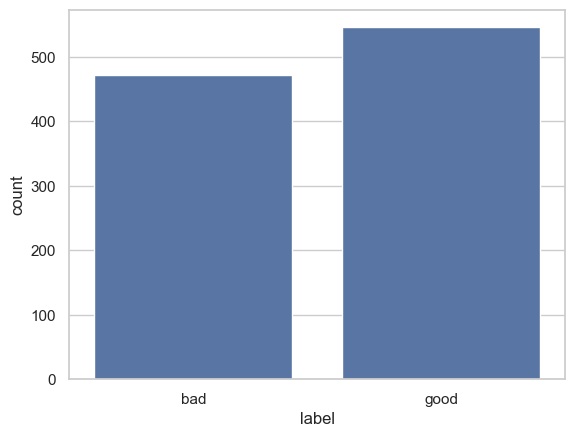

In [ ]:
sns.countplot(data=df, x="label", order=["bad", "good"])
plt.show()

Classes are fairly balanced (54% good, 46% bad), so accuracy is a fair metric.

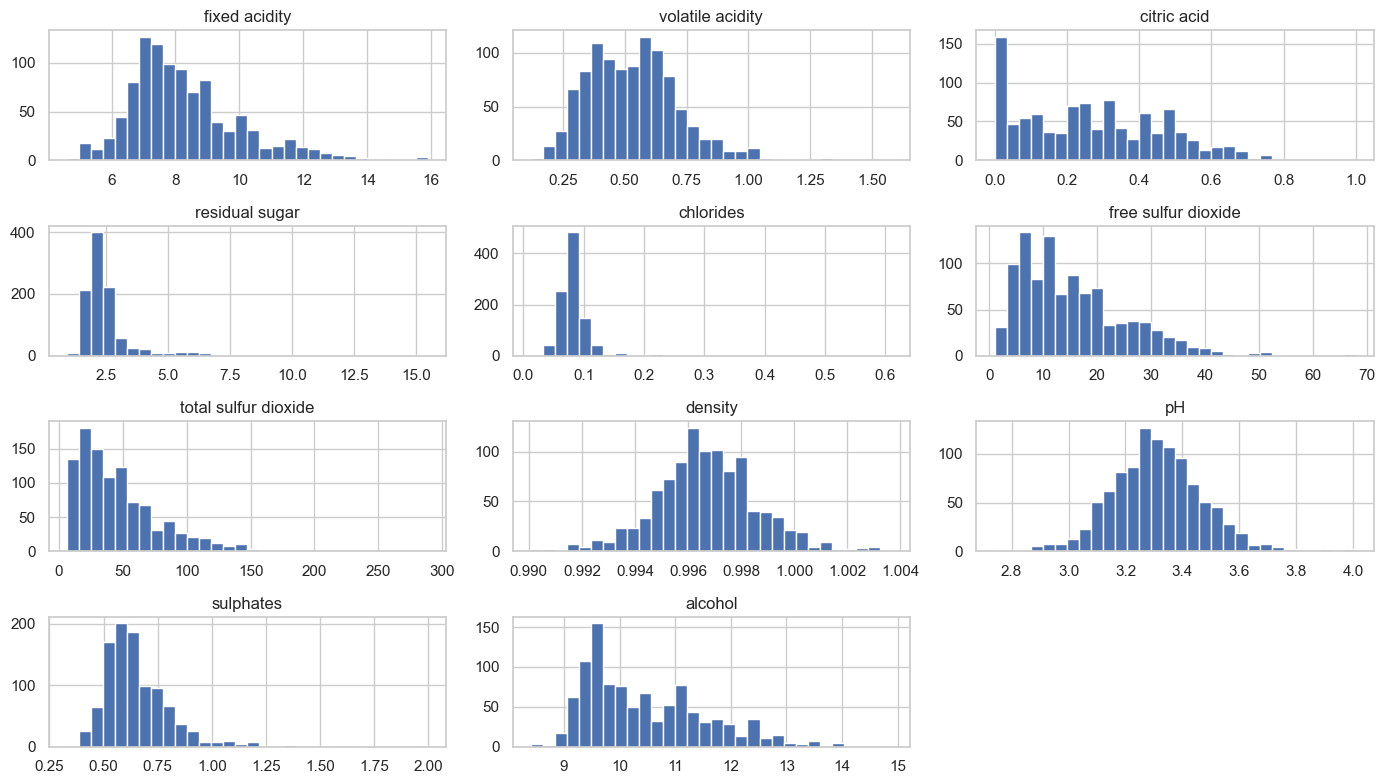

In [ ]:
df[FEATURES].hist(bins=30, figsize=(14, 8))
plt.tight_layout(); plt.show()

Residual sugar, chlorides, sulphates and total SO₂ are strongly right-skewed; density and pH are close to bell-shaped.

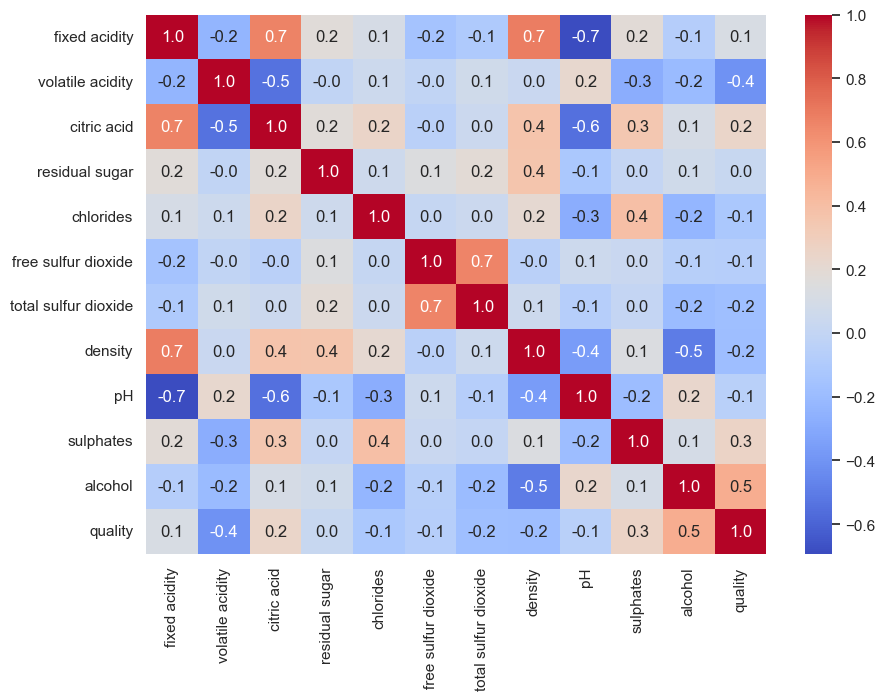

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[list(FEATURES) + ["quality"]].corr(), annot=True, fmt=".1f", cmap="coolwarm")
plt.show()

Alcohol (+0.49) and volatile acidity (−0.41) are the most related to quality. Some features are correlated with each other (fixed acidity with pH −0.69, density 0.68 and citric acid 0.67; free with total SO₂ 0.66), which Naive Bayes ignores.

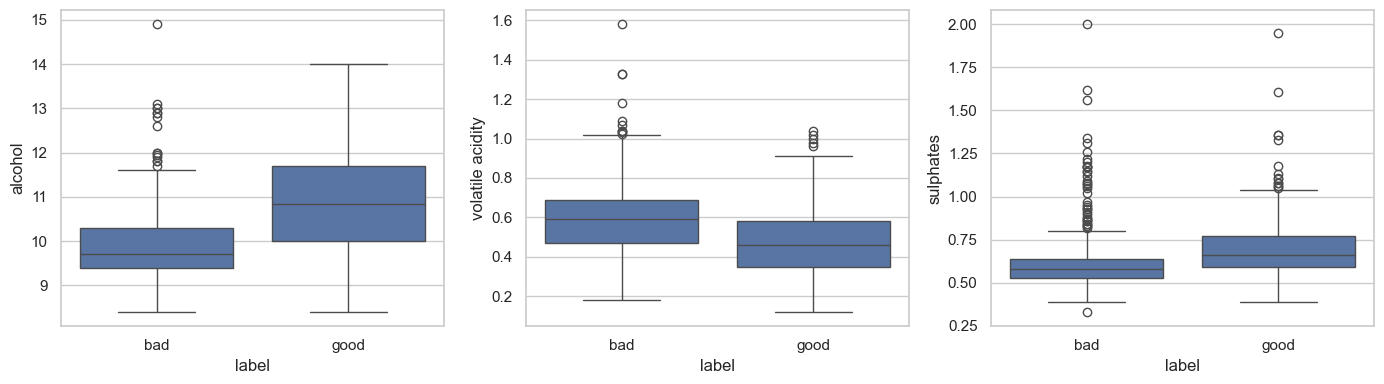

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["alcohol", "volatile acidity", "sulphates"]):
    sns.boxplot(data=df, x="label", y=col, order=["bad", "good"], ax=ax)
plt.tight_layout(); plt.show()

Good wines have more alcohol (median 10.85 vs 9.70), less volatile acidity (0.46 vs 0.59) and more sulphates (0.66 vs 0.58).

## 3. Gaussian Naive Bayes

In [ ]:
X, y = df[FEATURES], df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = GaussianNB().fit(X_train, y_train)
pred = model.predict(X_test)

print("Baseline (always guess the most common class):", round(y_test.value_counts(normalize=True).max(), 3))
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred))

Baseline (always guess the most common class): 0.534
Accuracy: 0.73
              precision    recall  f1-score   support

         bad       0.68      0.79      0.73        95
        good       0.79      0.68      0.73       109

    accuracy                           0.73       204
   macro avg       0.73      0.73      0.73       204
weighted avg       0.74      0.73      0.73       204



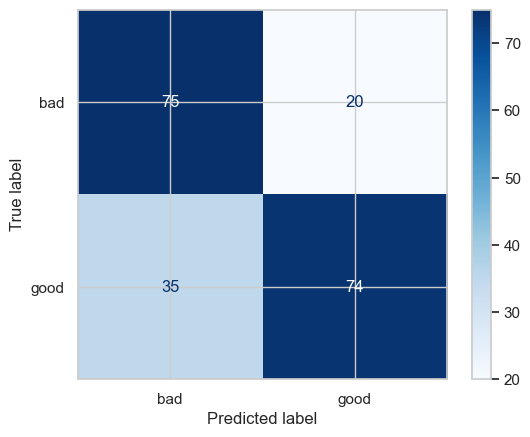

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=["bad", "good"], cmap="Blues")
plt.show()

In [ ]:

cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = cross_val_score(GaussianNB(), X, y, cv=cv)
print("5-fold accuracy:", scores.round(3), "| mean:", scores.mean().round(3))

5-fold accuracy: [0.691 0.706 0.696 0.759 0.729] | mean: 0.716


## 4. Bonus: generate new samples

In [ ]:

rng = np.random.default_rng(0)
k = rng.choice(len(model.classes_), size=len(X_train), p=model.class_prior_)

synth = pd.DataFrame(rng.normal(model.theta_[k], np.sqrt(model.var_[k])), columns=FEATURES)
synth = synth.clip(lower=X_train.min(), upper=X_train.max(), axis=1)
synth["label"] = model.classes_[k]
synth.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,label
0,9.910708,0.300263,0.196703,1.186038,0.034000,16.082840,17.837623,0.997838,3.304868,0.746486,10.601701,good
1,7.120931,0.579048,0.232910,1.621661,0.113335,24.505933,59.158147,1.000293,3.217591,0.699989,9.625567,bad
2,8.491550,0.441851,0.436920,2.741237,0.152769,2.655172,35.825011,0.995309,3.232857,0.495408,9.856004,bad
3,8.094567,0.588269,0.132641,2.755715,0.136461,6.604982,53.529168,0.996874,3.384955,0.601433,9.939862,bad
4,6.610974,0.478097,0.112064,3.172635,0.079201,15.476641,13.519789,0.998239,3.415607,0.809779,13.444479,good


In [ ]:
pd.DataFrame({"real mean": X_train.mean(), "synthetic mean": synth[FEATURES].mean()}).round(3)

,real mean,synthetic mean
fixed acidity,8.297,8.313
volatile acidity,0.531,0.518
citric acid,0.268,0.277
residual sugar,2.515,2.601
chlorides,0.087,0.088
free sulfur dioxide,15.695,16.353
total sulfur dioxide,45.358,47.967
density,0.997,0.997
pH,3.311,3.317
sulphates,0.653,0.665


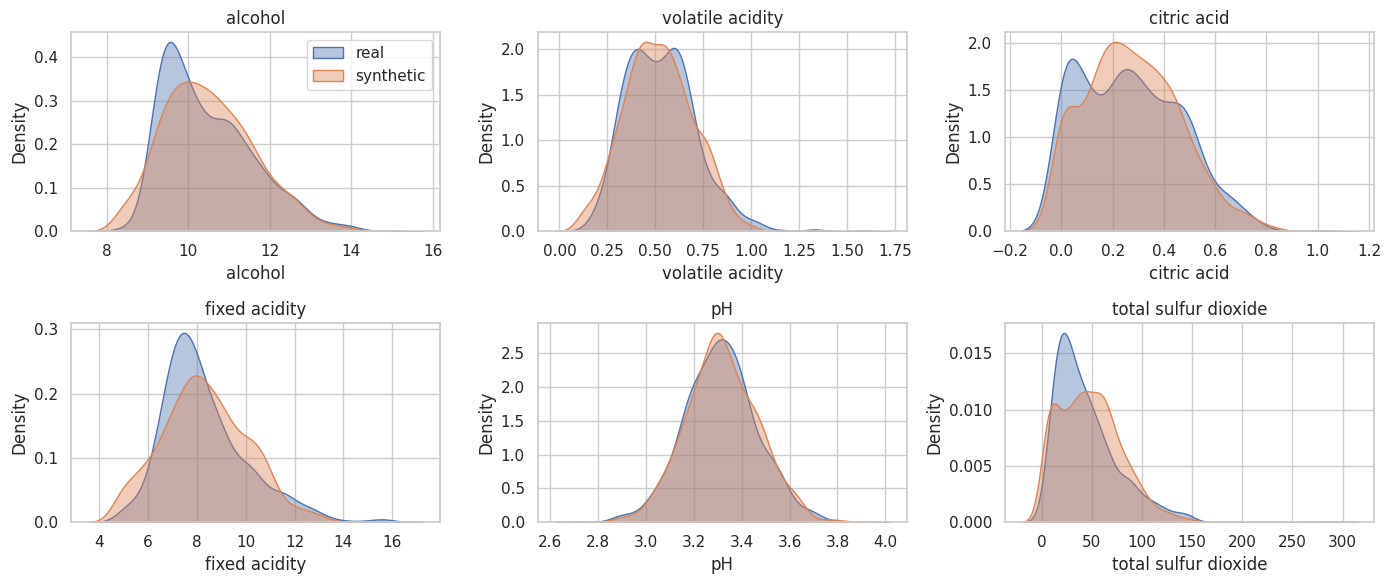

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), ["alcohol", "volatile acidity", "citric acid", "fixed acidity", "pH", "total sulfur dioxide"]):
    sns.kdeplot(X_train[col], ax=ax, label="real", fill=True, alpha=.4)
    sns.kdeplot(synth[col], ax=ax, label="synthetic", fill=True, alpha=.4)
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

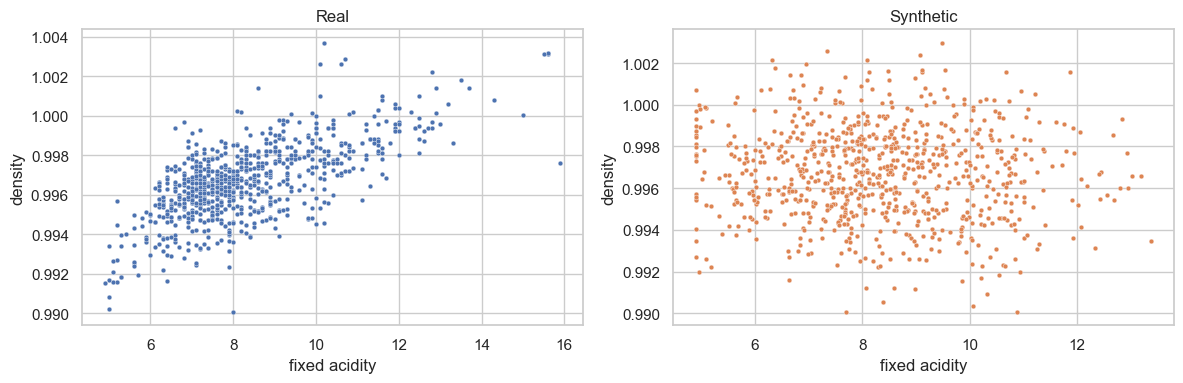

corr(fixed acidity, density)  real: 0.67  synthetic: -0.06
free SO2 > total SO2 (impossible)  real: 0  synthetic: 162


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=X_train, x="fixed acidity", y="density", ax=axes[0], s=12); axes[0].set_title("Real")
sns.scatterplot(data=synth, x="fixed acidity", y="density", ax=axes[1], s=12, color="C1"); axes[1].set_title("Synthetic")
plt.tight_layout(); plt.show()

print("corr(fixed acidity, density)  real:", round(X_train["fixed acidity"].corr(X_train["density"]), 2), " synthetic:", round(synth["fixed acidity"].corr(synth["density"]), 2))
print("free SO2 > total SO2 (impossible)  real:", (X_train["free sulfur dioxide"] > X_train["total sulfur dioxide"]).sum(), " synthetic:", (synth["free sulfur dioxide"] > synth["total sulfur dioxide"]).sum())

In [ ]:

synth_model = GaussianNB().fit(synth[FEATURES], synth["label"])
print("Trained on synthetic -> test accuracy:", round(accuracy_score(y_test, synth_model.predict(X_test)), 3))
print("Trained on real      -> test accuracy:", round(accuracy_score(y_test, pred), 3))

Trained on synthetic -> test accuracy: 0.701
Trained on real      -> test accuracy: 0.73


**Why this method works.** Naive Bayes is a *generative* model: after fitting, it stores the probability of each class and a mean and spread for every feature in every class. So a new wine can be made in two steps: pick good/bad using the class probabilities, then draw each feature from that class's normal distribution. The model was fitted on the training data only, and values are clipped to the real minimum and maximum so nothing goes outside what was actually observed.

**What the generated data look like.**
- Each feature has about the same average as the real data (e.g. alcohol 10.50 vs 10.48).
- Most of the good/bad information is kept: a model trained only on generated wines scores 0.701 on the real test set, close to a model trained on real wines (0.730).
- The features are not related to each other: fixed acidity vs density has a correlation of 0.67 in real data but about 0 in generated data. Because of this, 162 generated wines are impossible (free SO₂ higher than total SO₂).

**Why.** Naive Bayes assumes the features are independent once the class is known, and that each one follows a bell curve. So it keeps what it stores (class probabilities, averages, spreads) and loses what it ignores (relationships between features). This is the expected behaviour of the model, and it is why the generated data are good for class-level statistics but not realistic as individual wines.